In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import os
import numpy as np

Number of columns: 5
Column names: ['"datetime[ISO8601]', 'seafloor_pressure_abs_quality_controlled[dbar]', 'seafloor_pressure_abs_modelled[dbar]', 'seafloor_pressure_residual[dbar]', 'temperature[K]"']
1048575
Rows after cleaning datetime: 1048575
                     Residual
Datetime                     
2010-02-27 00:00:00    0.0069
2010-02-27 00:00:15    0.0063
2010-02-27 00:00:30    0.0069
2010-02-27 00:00:45    0.0066
2010-02-27 00:01:00    0.0059
...                       ...
2010-02-27 23:58:45    0.0180
2010-02-27 23:59:00    0.0186
2010-02-27 23:59:15    0.0190
2010-02-27 23:59:30    0.0207
2010-02-27 23:59:45    0.0210

[5760 rows x 1 columns]
                     Residual
Datetime                     
2009-10-27 00:00:00    0.0361
2009-10-27 00:00:15    0.0361
2009-10-27 00:00:30    0.0358
2009-10-27 00:00:45    0.0358
2009-10-27 00:01:00    0.0354
...                       ...
2009-10-27 23:58:45    0.0177
2009-10-27 23:59:00    0.0177
2009-10-27 23:59:15    0.0187
2009-1

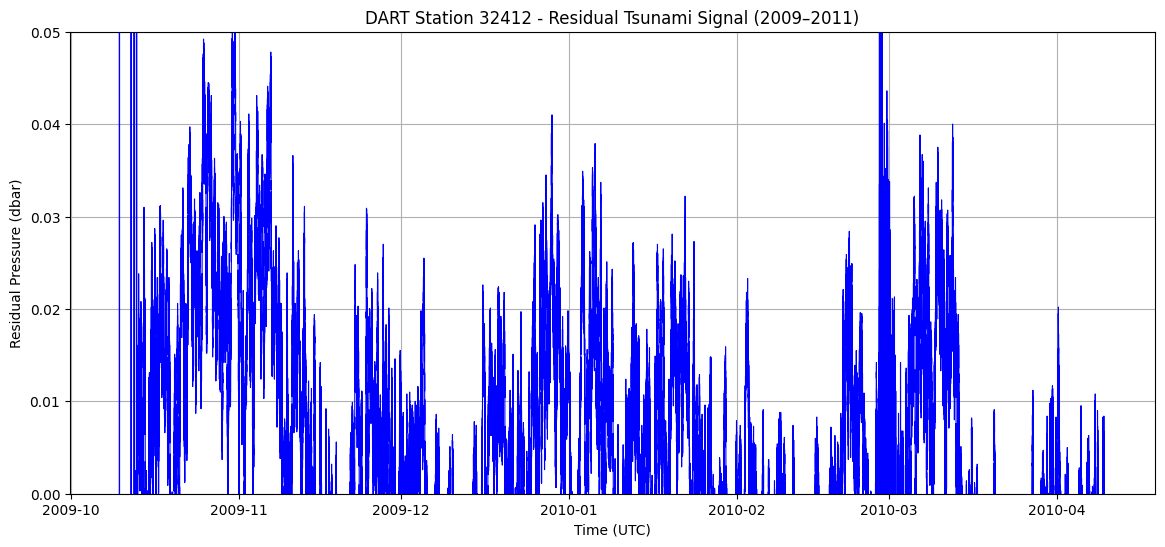

In [3]:
#  Path to your CSV file
file_path = r"C:\Users\Deepthi Ravichandran\Desktop\SP_project\32412_20091009to20110503_qc.csv\32412_20091009to20110503_qc.csv"

# Read the CSV with proper delimiter
df = pd.read_csv(file_path, sep=r"\s+", engine="python")

# Inspect columns
print("Number of columns:", len(df.columns))
print("Column names:", df.columns.tolist())


# Keep only first 4 (Datetime, Obs, Tide, Residual)
df = df.iloc[:, :4]   # take only first 4 columns

# Rename them
df.columns = ["Datetime", "Obs", "Tide", "Residual"]

print( len(df))

#  Convert datetime column
# Convert datetime without strict format
df["Datetime"] = pd.to_datetime(df["Datetime"], format="%Y-%m-%dT%H:%M:%SZ", errors="coerce", exact=False)


# Drop rows with invalid datetime (NaT)
df.dropna(subset=["Datetime"], inplace=True)

print(f"Rows after cleaning datetime: {len(df)}")

# Step 8: Set index
df.set_index("Datetime", inplace=True)

# Step 9: Keep only Residual
df = df[["Residual"]]

#Show preview
'''print(df.head())
print(df.info())'''

specific_date_data = df.loc['2010-02-27']
print(specific_date_data)

specific_date_data = df.loc['2009-10-27']
print(specific_date_data)

# Plot
plt.figure(figsize=(14,6))
plt.plot(df.index, df["Residual"], color="blue", linewidth=0.8)
plt.title("DART Station 32412 - Residual Tsunami Signal (2009–2011)")
plt.xlabel("Time (UTC)")
plt.ylabel("Residual Pressure (dbar)")
plt.ylim(0, 0.05)  # Set appropriate y-axis for residuals
plt.grid()
plt.show()



Datetime index sample:
DatetimeIndex(['2009-10-09 23:35:00', '2009-10-09 23:35:15',
               '2009-10-09 23:35:30', '2009-10-09 23:35:45',
               '2009-10-09 23:36:00'],
              dtype='datetime64[ns]', name='Datetime', freq=None)
Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Extracted event shape: (5761, 1)
                     Residual
Datetime                     
2010-02-27 00:00:00    0.0069
2010-02-27 00:00:15    0.0063
2010-02-27 00:00:30    0.0069
2010-02-27 00:00:45    0.0066
2010-02-27 00:01:00    0.0059
                     Residual
Datetime                     
2010-02-27 23:59:00    0.0186
2010-02-27 23:59:15    0.0190
2010-02-27 23:59:30    0.0207
2010-02-27 23:59:45    0.0210
2010-02-28 00:00:00    0.0207


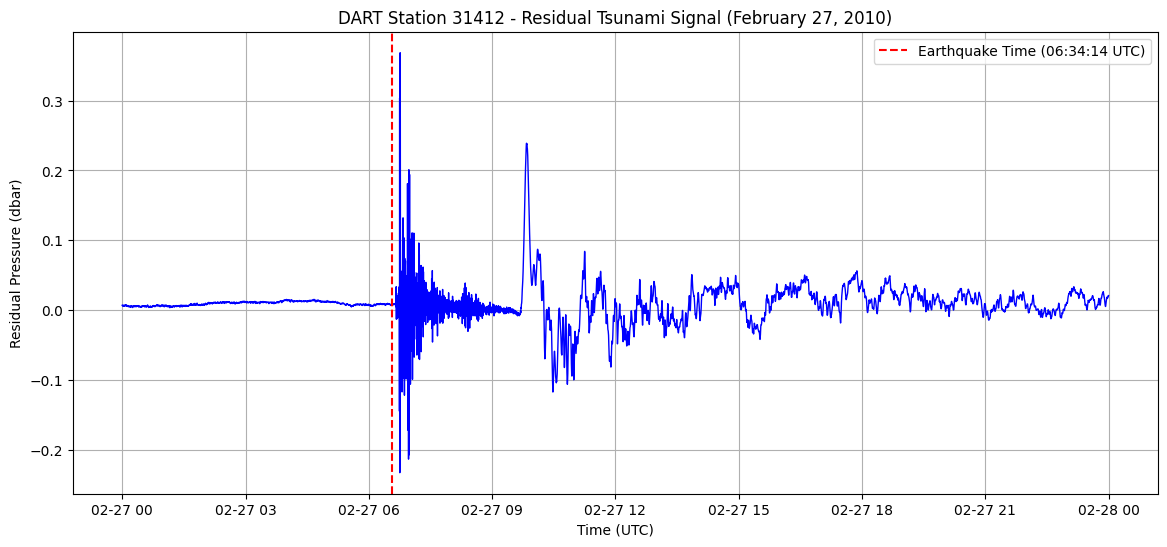

In [40]:
# Debug datetime index

print("\nDatetime index sample:")
print(df.index[:5])
print("Index type:", type(df.index))

# Extract February 27, 2010 event
# Adjust if timezone is included (+00:00)
start = "2010-02-27 00:00:00"
end   = "2010-02-28 00:00:00"

df_event = df.loc[start:end]

print("\nExtracted event shape:", df_event.shape)
print(df_event.head())
print(df_event.tail())


# Plot February 27, 2010 event

plt.figure(figsize=(14,6))
plt.plot(df_event.index, df_event["Residual"], color="blue", linewidth=1)
plt.axvline(pd.Timestamp("2010-02-27 06:34:12"), color="red", linestyle="--", label="Earthquake Time (06:34:14 UTC)")
plt.title("DART Station 31412 - Residual Tsunami Signal (February 27, 2010)")
plt.xlabel("Time (UTC)")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid()
plt.show()

C:\Users\Deepthi Ravichandran\AppData\Local\Temp\ipykernel_18900\880406546.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event["Smoothed"] = df_event["Residual"].rolling(window=window_size, center=True).mean()


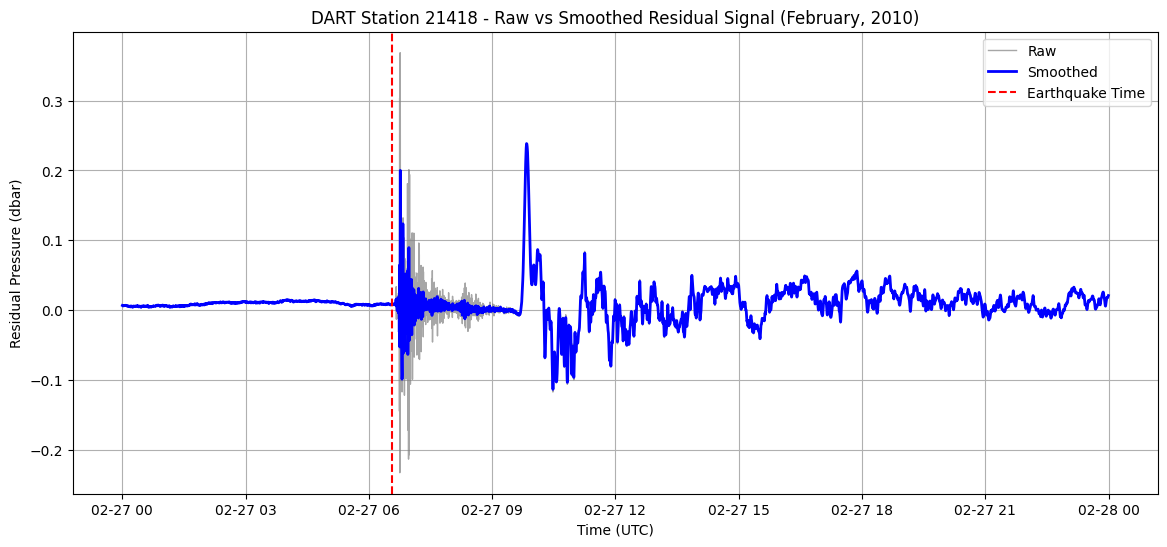

In [41]:


# Smooth with rolling window

window_size = 3  # 3 samples → 45 sec smoothing
df_event["Smoothed"] = df_event["Residual"].rolling(window=window_size, center=True).mean()


# Plot raw vs smoothed
plt.figure(figsize=(14,6))
plt.plot(df_event.index, df_event["Residual"], color="gray", linewidth=1, alpha=0.7, label="Raw")
plt.plot(df_event.index, df_event["Smoothed"], color="blue", linewidth=2, label="Smoothed")
plt.axvline(pd.Timestamp("2010-02-27 06:34:12"), color="red", linestyle="--", label="Earthquake Time")
plt.title("DART Station 21418 - Raw vs Smoothed Residual Signal (February, 2010)")
plt.xlabel("Time (UTC)")
plt.ylabel("Residual Pressure (dbar)")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
pip install GitPython


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install numba


   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 2.7/2.7 MB 19.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/37.9 MB ? eta -:--:--
   -------- ------------------------------- 8.1/37.9 MB 35.9 MB/s eta 0:00:01
   --------------- ------------------------ 14.4/37.9 MB 33.5 MB/s eta 0:00:01
   ----------------------- ---------------- 22.0/37.9 MB 34.8 MB/s eta 0:00:01
   ------------------------------- -------- 30.1/37.9 MB 36.1 MB/s eta 0:00:01
   ---------------------------------------  37.7/37.9 MB 36.4 MB/s eta 0:00:01
   ---------------------------------------  37.7/37.9 MB 36.4 MB/s eta 0:00:01
   ---------------------------------------- 37.9/37.9 MB 28.7 MB/s eta 0:00:00

   ---------------------------------------- 0/2 [llvmlite]
   ---------------------------------------- 0/2 [llvmlite]
   ---------------------------------------- 0/2 [llvmlite]
   ---------------------------------------- 0/2 [llvml


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


IMF 1
IMF 2
IMF 3
IMF 4
IMF 5
IMF 6
IMF 7
IMF 8
IMF 9
IMF 10
IMF 11
IMF 12
IMF 13
IMF 14
IMF 15
IMF 16
IMF 17
IMF 18
IMF 19
IMF 20
IMF 21
IMF 22
IMF 23
IMF 24
IMF 25
IMF 26
IMF 27
IMF 28
IMF 29
IMF 30
IMF 31
IMF 32
IMF 33
IMF 34
IMF 35
IMF 36
IMF 37
IMF 38
IMF 39
IMF 40
IMF 41
IMF 42
IMF 43
IMF 44
IMF 45
IMF 46
IMF 47
IMF 48
IMF 49
IMF 50
IMF 51
IMF 52
IMF 53
IMF 54
IMF 55
IMF 56
IMF 57
IMF 58
IMF 59
IMF 60
Max # of inner steps reached
IMF 61
Max # of inner steps reached
IMF 62
Max # of inner steps reached
IMF 63
IMF 64
IMF 65


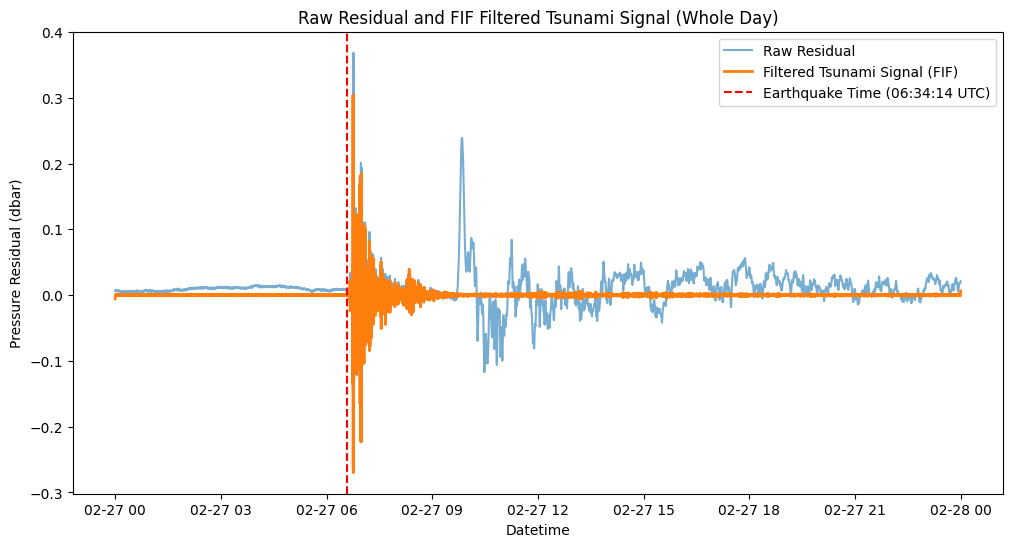

In [45]:
from numpy.polynomial import Polynomial

# Import FIF class from the repository module
from FIF.FIF_main import FIF

#  Select recent event window (3 hours or desired length)
start_time = pd.Timestamp('2010-02-27 00:00:00')
end_time = pd.Timestamp('2010-02-28 00:00:00')

# Filter dataframe df for the specified time range
df_filtered = df.loc[(df.index >= start_time) & (df.index < end_time)].copy()
# 2. Polynomial detrend to remove tides/long-term background
times = np.arange(len(df_filtered))
pfit = Polynomial.fit(times, df_filtered['Residual'].values, deg=3)
detrended = df_filtered['Residual'] - pfit(times)

# 3. Instantiate FIF class and run filtering
fif_filter = FIF()
fif_filter.run(detrended.values)

# 4. Retrieve IMFs and sum first 3 components as tsunami signal (adjust as needed)
imfs = fif_filter.data['IMC']
tsunami_signal = np.sum(imfs[:3, :], axis=0)

# 5. Add filtered tsunami signal as new column to df_day
df_filtered = df_filtered.copy()
df_filtered['Tsunami_Signal'] = tsunami_signal

# 6. Plot raw residual and filtered tsunami signal together
plt.figure(figsize=(12, 6))
plt.plot(df_filtered.index, df_filtered['Residual'], label='Raw Residual', alpha=0.6)
plt.plot(df_filtered.index, df_filtered['Tsunami_Signal'], label='Filtered Tsunami Signal (FIF)', linewidth=2)

# 7. Plot earthquake timestamp as vertical line
plt.axvline(pd.Timestamp("2010-02-27 06:34:12"), color="red", linestyle="--", label="Earthquake Time (06:34:14 UTC)")

plt.title('Raw Residual and FIF Filtered Tsunami Signal (Whole Day)')
plt.xlabel('Datetime')
plt.ylabel('Pressure Residual (dbar)')
plt.legend()
plt.show()






STA (non-NaN values):
Datetime
2010-02-27 00:05:00   -0.000184
2010-02-27 00:05:15   -0.000034
2010-02-27 00:05:30    0.000061
2010-02-27 00:05:45    0.000071
2010-02-27 00:06:00    0.000038
                         ...   
2010-02-27 23:54:00   -0.000058
2010-02-27 23:54:15   -0.000084
2010-02-27 23:54:30   -0.000092
2010-02-27 23:54:45    0.000014
2010-02-27 23:55:00    0.000198
Name: Tsunami_Signal, Length: 5721, dtype: float64


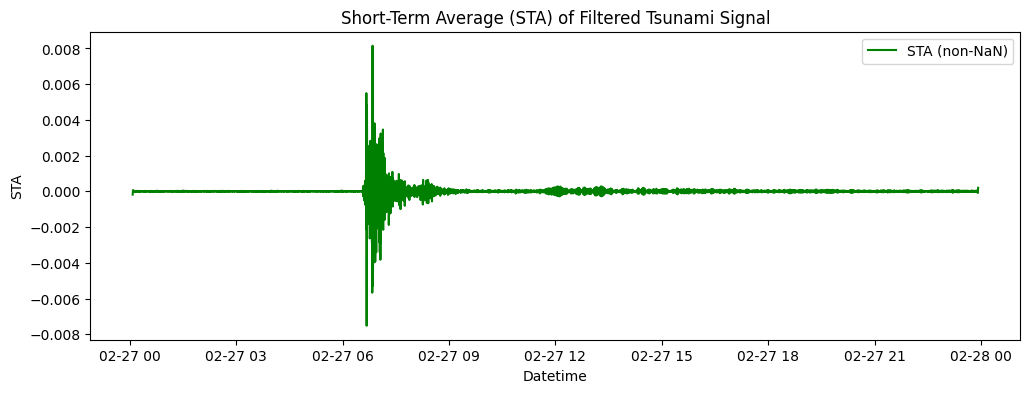

RMS (non-NaN values):
Datetime
2010-02-27 00:05:00    0.001161
2010-02-27 00:05:15    0.000697
2010-02-27 00:05:30    0.000464
2010-02-27 00:05:45    0.000464
2010-02-27 00:06:00    0.000430
                         ...   
2010-02-27 23:54:00    0.000636
2010-02-27 23:54:15    0.000656
2010-02-27 23:54:30    0.000654
2010-02-27 23:54:45    0.000834
2010-02-27 23:55:00    0.001289
Name: Tsunami_Signal, Length: 5721, dtype: float64


"# Assume df_filtered is your dataframe with filtered tsunami signal as 'Tsunami_Signal' column\n\n# Calculate sampling interval in seconds (assuming datetime index)\ndt_seconds = (df_filtered.index[1] - df_filtered.index[0]).total_seconds()\n\n# Define STA window in samples (e.g., 10 minutes)\nsta_window = int(10 * 60 / dt_seconds)\n\nimport numpy as np\n\n# Define RMS function\nrms_func = lambda x: np.sqrt(np.mean(x ** 2))\n\n# Calculate STA with rolling mean, centered\nsta = df_filtered['Tsunami_Signal'].rolling(window=sta_window, center=True).mean()\n\n# Calculate RMS with rolling apply, centered\nrms = df_filtered['Tsunami_Signal'].rolling(window=sta_window, center=True).apply(rms_func)\n\n# Filter out NaNs before display or plot\nsta_non_nan = sta[sta.notna()]\nrms_non_nan = rms[rms.notna()]\n\nprint('STA (non-NaN values):')\nprint(sta_non_nan)\n\nprint('RMS (non-NaN values):')\nprint(rms_non_nan)\n\n# Plotting STA (non-NaN)\nimport matplotlib.pyplot as plt\n\nplt.figure(figsize=

In [7]:
# Assuming df_filtered is already filtered for time range and has 'Residual' and 'Tsunami_Signal'

# Calculate sampling interval in seconds from DataFrame index
dt_seconds = (df_filtered.index[1] - df_filtered.index[0]).total_seconds()

# Define STA window in number of samples (e.g., for 10 minutes window)
sta_window = int(10 * 60 / dt_seconds)

# Function to compute RMS of a numpy array
rms_func = lambda x: np.sqrt(np.mean(x**2))

# Calculate Short-Term Average (STA) with rolling mean, centered relative to window
sta = pd.Series(df_filtered['Tsunami_Signal']).rolling(window=sta_window, center=True).mean()

# Calculate RMS with rolling apply of custom function, centered
rms = pd.Series(df_filtered['Tsunami_Signal']).rolling(window=sta_window, center=True).apply(rms_func)

# Display non-NaN STA values with timestamps
sta_non_nan = sta[sta.notna()]
print('STA (non-NaN values):')
print(sta_non_nan)

# Optionally plot STA (non-NaN) against time
plt.figure(figsize=(12, 4))
plt.plot(sta_non_nan.index, sta_non_nan.values, label='STA (non-NaN)', color='green')
plt.title('Short-Term Average (STA) of Filtered Tsunami Signal')
plt.xlabel('Datetime')
plt.ylabel('STA')
plt.legend()
plt.show()

# Similarly print RMS non-NaN values if desired
rms_non_nan = rms[rms.notna()]
print('RMS (non-NaN values):')
print(rms_non_nan)



In [2]:
pip install scikit-learn


  Using cached scikit_learn-1.7.2-cp312-cp312-win_amd64.whl.metadata (11 kB)
  Using cached joblib-1.5.2-py3-none-any.whl.metadata (5.6 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.7 MB ? eta -:--:--
   -------------------------- ------------- 5.8/8.7 MB 35.3 MB/s eta 0:00:01
   ---------------------------------------- 8.7/8.7 MB 30.1 MB/s eta 0:00:00

   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [jobli


[notice] A new release of pip is available: 25.1.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [15 lines of output]
  The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
  rather than 'sklearn' for pip commands.
  
  Here is how to fix this error in the main use cases:
  - use 'pip install scikit-learn' rather than 'pip install sklearn'
  - replace 'sklearn' by 'scikit-learn' in your pip requirements files
    (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
  - if the 'sklearn' package is used by one of your dependencies,
    it would be great if you take some time to track which package uses
    'sklearn' instead of 'scikit-learn' and report it to their issue tracker
  - as a last resort, set the environment variable
    SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
  
  More information is available at
  https://github.com/scikit-learn/sklearn-pypi-package
  [end of output]
  
  note: This error originates f

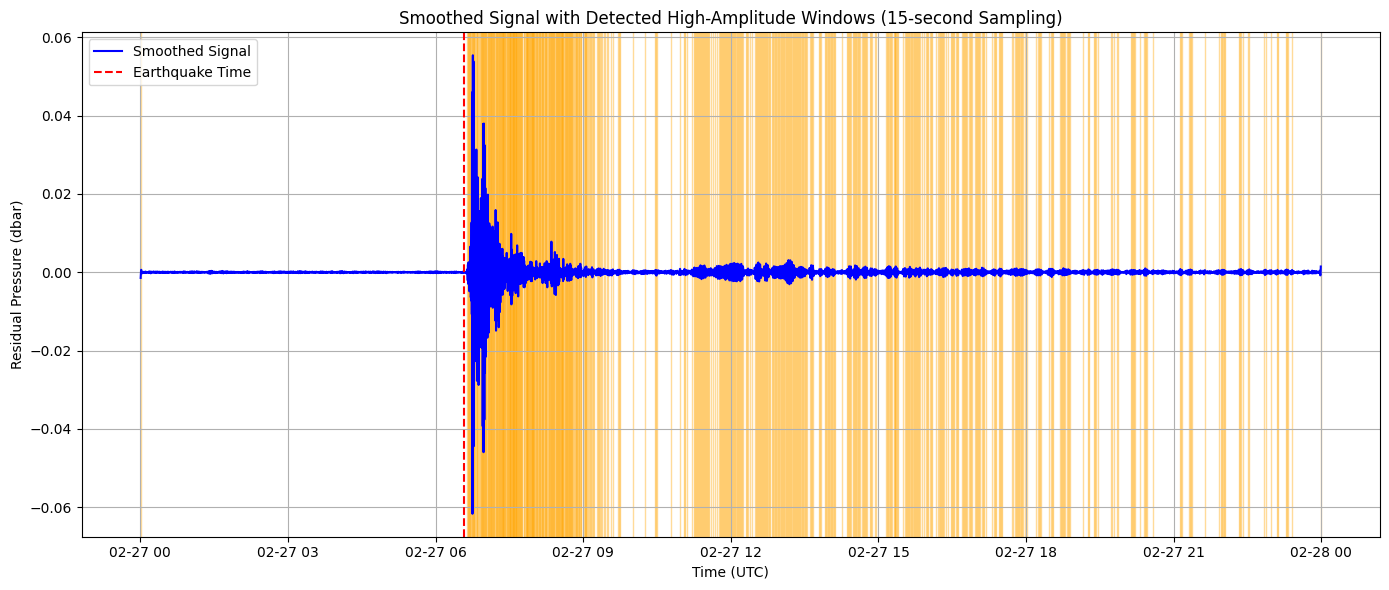

In [38]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Example inputs from your processed data:
# df_filtered (with 'Tsunami_Signal' and datetime index)
# earthquake_time as pd.Timestamp
earthquake_time = pd.Timestamp("2010-02-27 06:34:12")  # adjust accordingly

# Resample the signal to 15-second intervals (mean aggregation)
df_resampled = df_filtered['Tsunami_Signal'].resample('15s').mean().dropna()

# Smooth the resampled signal with a rolling mean (window size can be adjusted)
smoothed_signal = df_resampled.rolling(window=5, center=True).mean()

# Define threshold to detect high-amplitude windows
threshold = 0.0005  # adjust based on data scale

# Find windows above threshold
above_threshold = smoothed_signal > threshold

# Find continuous segments/windows where above_threshold True
diff = above_threshold.astype(int).diff()
start_indices = diff[diff == 1].index
end_indices = diff[diff == -1].index

# Fix edge cases if signal starts or ends above threshold
if above_threshold.iloc[0]:
    start_indices = start_indices.insert(0, smoothed_signal.index[0])
if above_threshold.iloc[-1]:
    end_indices = end_indices.insert(len(end_indices), smoothed_signal.index[-1])

# Plotting
plt.figure(figsize=(14, 6))
plt.plot(smoothed_signal.index, smoothed_signal, label='Smoothed Signal', color='blue')

# Plot earthquake time as vertical dashed line
plt.axvline(earthquake_time, color='red', linestyle='--', label='Earthquake Time')

# Highlight windows with high amplitude
for start, end in zip(start_indices, end_indices):
    plt.axvspan(start, end, color='orange', alpha=0.4)

plt.title('Smoothed Signal with Detected High-Amplitude Windows (15-second Sampling)')
plt.xlabel('Time (UTC)')
plt.ylabel('Residual Pressure (dbar)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [39]:
import numpy as np
import pandas as pd
from math import radians, sin, cos, sqrt, asin
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks
from scipy.fft import rfft, rfftfreq


# Define the start and end times for the window
start_time = df_filtered.index[0].replace(hour=3, minute=0, second=0)
end_time = start_time + pd.Timedelta(hours=7)  # 6 hours from 04:00 to 10:00

# Resample the data to 15-second intervals using mean aggregation
df_resampled = df_filtered.loc[start_time:end_time, 'Tsunami_Signal'].resample('15s').mean().dropna()

window_signal = df_resampled.values
window_time = df_resampled.index

# Calculate dt_seconds for the resampled data
dt_seconds = (window_time[1] - window_time[0]).total_seconds()

# Statistical features
max_amp = np.max(window_signal)
min_amp = np.min(window_signal)
mean_amp = np.mean(window_signal)
std_amp = np.std(window_signal)
skew_amp = skew(window_signal)
kurt_amp = kurtosis(window_signal)
peak_to_peak = max_amp - min_amp
rms_amp = np.sqrt(np.mean(window_signal ** 2))

# Onset time using a smaller threshold for sensitivity
threshold = 0.005  # Adjust as needed
indices_above_thresh = np.where(np.abs(window_signal) > threshold)[0]
onset_time_relative = np.nan
if len(indices_above_thresh) > 0:
    onset_sample = indices_above_thresh[0]
    onset_time_relative = onset_sample * dt_seconds

# Peak detection
peaks, _ = find_peaks(window_signal)
rise_time = np.nan
if len(peaks) > 0 and len(indices_above_thresh) > 0:
    first_peak = peaks[0]
    if first_peak > indices_above_thresh[0]:
        rise_time = (first_peak - indices_above_thresh[0]) * dt_seconds

# STA/LTA with adjusted windows
sta_window_s = 300  # 5 minutes
lta_window_s = 1800  # 30 minutes

def rolling_mean(arr, window):
    return pd.Series(arr).rolling(window=window, center=True).mean().values

fs = 1 / dt_seconds
sta_samples = max(1, int(sta_window_s * fs))
lta_samples = max(1, int(lta_window_s * fs))

sta_vals = rolling_mean(window_signal, sta_samples)
lta_vals = rolling_mean(window_signal, lta_samples)
lta_vals_safe = np.where(lta_vals == 0, 1e-10, lta_vals)
sta_lta_ratio = sta_vals / lta_vals_safe

max_sta_lta = np.nanmax(sta_lta_ratio)
if np.all(np.isnan(sta_lta_ratio)):
    time_of_max_sta_lta = np.nan
else:
    time_of_max_sta_lta = np.nanargmax(sta_lta_ratio) * dt_seconds

sta_lta_triggered = int(max_sta_lta > 2.0) if not np.isnan(max_sta_lta) else 0

# Frequency domain features

fft_vals = rfft(window_signal)
freqs = rfftfreq(len(window_signal), d=dt_seconds)
power_spectrum = np.abs(fft_vals) ** 2

dominant_freq = freqs[np.argmax(power_spectrum)]
dominant_period = 1 / dominant_freq if dominant_freq != 0 else np.nan
spectral_centroid = np.sum(freqs * power_spectrum) / np.sum(power_spectrum)

# Event metadata remains unchanged
event_metadata = {
    'event_mag': 8.8,
    'event_depth': 35.0,
    'dist_epicenter_to_coast': 20000,
    'azimuth_epicenter_to_buoy': 45.0
}

# Assemble features
features = {
    'event_mag': event_metadata['event_mag'],
    'event_depth': event_metadata['event_depth'],
    'dist_epicenter_to_coast': event_metadata['dist_epicenter_to_coast'],
    'azimuth_epicenter_to_buoy': event_metadata['azimuth_epicenter_to_buoy'],
    'max_amp': max_amp,
    'min_amp': min_amp,
    'mean_amp': mean_amp,
    'std_amp': std_amp,
    'skew_amp': skew_amp,
    'kurt_amp': kurt_amp,
    'peak_to_peak': peak_to_peak,
    'rms_amp': rms_amp,
    'onset_time_relative': onset_time_relative,
    'rise_time': rise_time,
    'max_sta_lta': max_sta_lta,
    'time_of_max_sta_lta': time_of_max_sta_lta,
    'sta_lta_triggered': sta_lta_triggered,
    'dominant_period': dominant_period,
    'spectral_centroid': spectral_centroid
}

df_features = pd.DataFrame([features])
df_features.to_csv("engineered_tsunami_features_15s.csv", index=False)
print("Feature engineering with 15-second sampling interval complete:")
print(df_features)


Feature engineering with 15-second sampling interval complete:
   event_mag  event_depth  dist_epicenter_to_coast  azimuth_epicenter_to_buoy  \
0        8.8         35.0                    20000                       45.0   

    max_amp   min_amp      mean_amp   std_amp  skew_amp   kurt_amp  \
0  0.304241 -0.270097 -7.021912e-07  0.024503   0.60092  62.250923   

   peak_to_peak   rms_amp  onset_time_relative  rise_time  max_sta_lta  \
0      0.574339  0.024503              13185.0        NaN  2827.664256   

   time_of_max_sta_lta  sta_lta_triggered  dominant_period  spectral_centroid  
0               1155.0                  1        57.700229           0.018817  


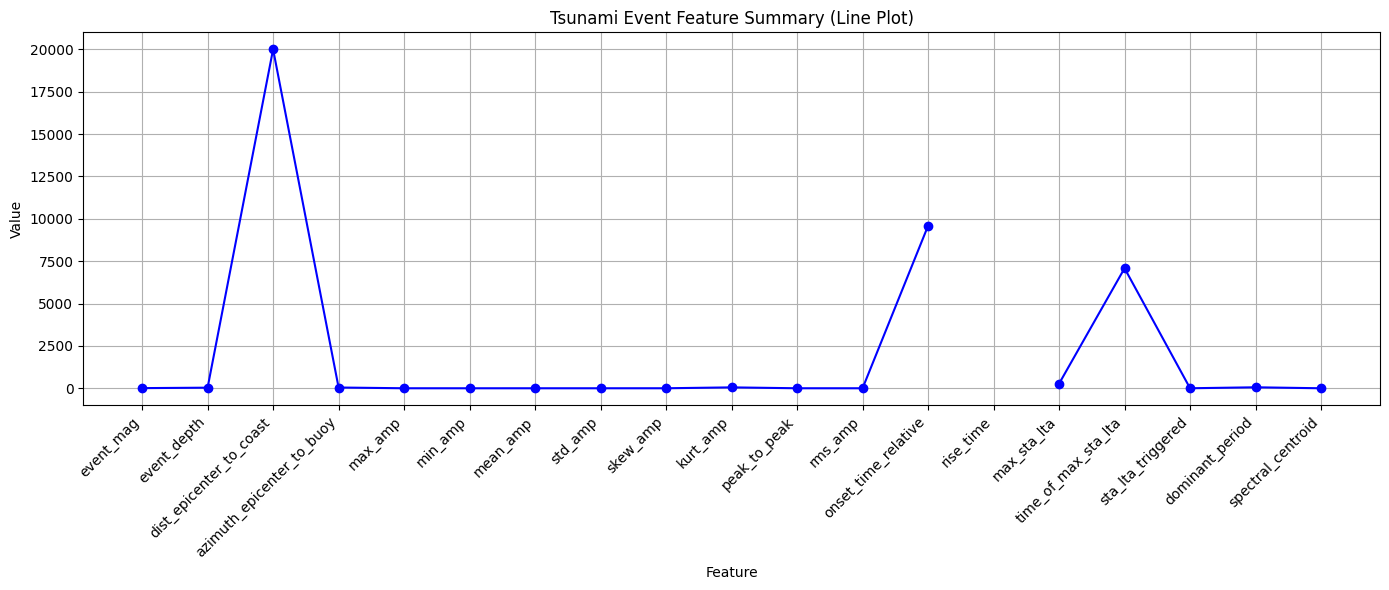

In [11]:
from sklearn.preprocessing import MinMaxScaler

# Remove any non-numeric columns if present
numeric_features = df_features.select_dtypes(include=['float64', 'int64']).columns

# Line plot with points for feature summary
plt.figure(figsize=(14, 6))
plt.plot(numeric_features, df_features.loc[0, numeric_features], marker='o', linestyle='-', color='blue')
plt.title("Tsunami Event Feature Summary (Line Plot)")
plt.xlabel("Feature")
plt.ylabel("Value")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()

plt.show()

# Window-wise feature visualization function (expects a datetime column and features)
def plot_window_features(df_windows_features, features_to_plot):
    plt.figure(figsize=(14, 6))
    for feat in features_to_plot:
        plt.plot(df_windows_features['window_start_time'], df_windows_features[feat], marker='o', linestyle='-', label=feat)
    plt.xlabel('Window Start Time')
    plt.ylabel('Feature Value')
    plt.title('Window-wise Feature Evolution')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Normalize and plot features function
def plot_normalized_features(df_features):
    df_norm = df_features.copy()
    numeric_cols = df_norm.select_dtypes(include=['float64', 'int64']).columns
    scaler = MinMaxScaler()
    df_norm[numeric_cols] = scaler.fit_transform(df_norm[numeric_cols])
    df_melted = df_norm.melt(var_name='Feature', value_name='Value')
    plt.figure(figsize=(12,6))
    plt.plot(df_melted['Feature'], df_melted['Value'], 'o-', color='blue')
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('Normalized Value (0–1)')
    plt.title('Tsunami Event Feature Summary (Normalized)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()





Sample wave heights (m):
Datetime
2010-02-27 00:00:00   -0.005842
2010-02-27 00:00:15   -0.003307
2010-02-27 00:00:30   -0.000168
2010-02-27 00:00:45    0.001117
2010-02-27 00:01:00    0.000980
Name: Wave_Height_m, dtype: float64

Sample coastal wave heights (m):
Datetime
2010-02-27 00:00:00   -0.016014
2010-02-27 00:00:15   -0.009063
2010-02-27 00:00:30   -0.000462
2010-02-27 00:00:45    0.003060
2010-02-27 00:01:00    0.002685
Name: Wave_Height_Coast_m, dtype: float64

Estimated tsunami wave speed in deep ocean (m/s): 235.32
Estimated tsunami wave speed near coast (m/s): 31.32


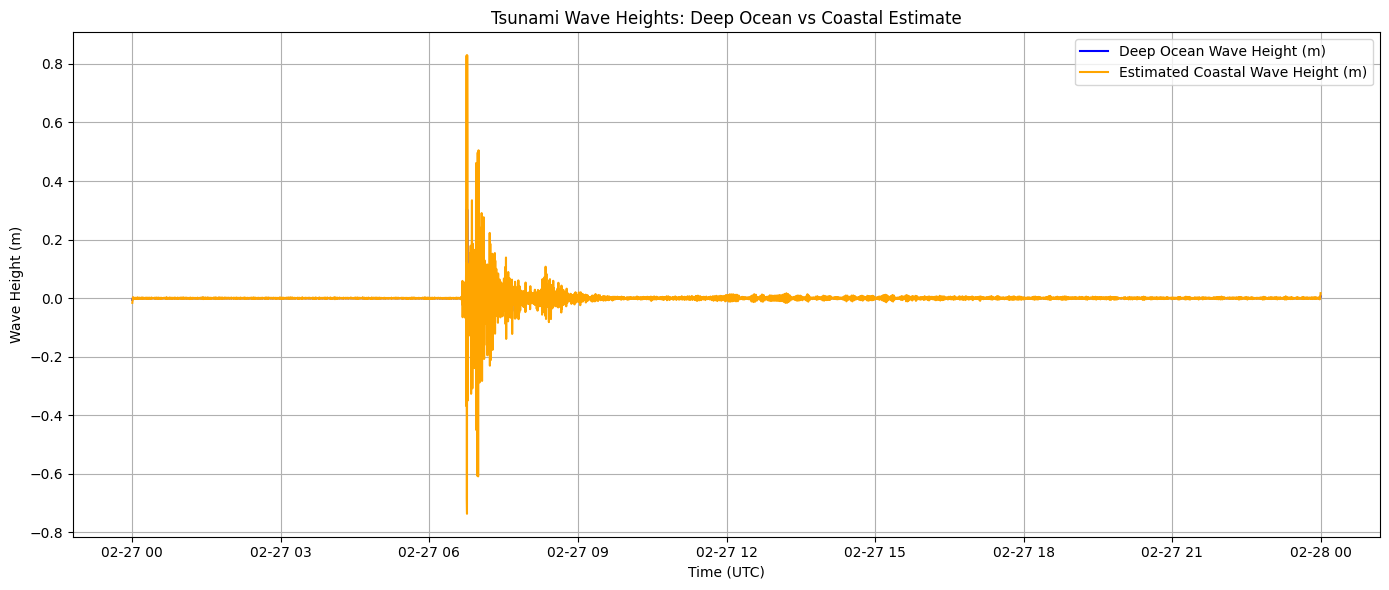

In [37]:
# Constants
rho = 1025  # Seawater density, kg/m^3
g = 9.81    # Gravitational acceleration, m/s^2

# Convert residual pressure (dbar) to tsunami wave height (meters)
# Using df_filtered which contains 'Tsunami_Signal' column with filtered residual pressure
# Scale factor to convert dbar to Pascals: 1 dbar = 10000 Pascals (N/m^2)

# Convert filtered residual from dbar to wave height in meters
df_filtered['Wave_Height_m'] = df_filtered['Tsunami_Signal'] * 10000 / (rho * g)

print("Sample wave heights (m):")
print(df_filtered['Wave_Height_m'].head())

# Step 6: Estimate coastal wave height using Green's law
h_deep = 5645  # Deep ocean depth in meters (example)
h_coast = 100  # Nearshore depth in meters (example)

df_filtered['Wave_Height_Coast_m'] = df_filtered['Wave_Height_m'] * (h_deep / h_coast)**0.25

print("\nSample coastal wave heights (m):")
print(df_filtered['Wave_Height_Coast_m'].head())

# Step 7: Calculate wave speeds in deep ocean and near coast
c_deep = np.sqrt(g * h_deep)
c_coast = np.sqrt(g * h_coast)

print(f"\nEstimated tsunami wave speed in deep ocean (m/s): {c_deep:.2f}")
print(f"Estimated tsunami wave speed near coast (m/s): {c_coast:.2f}")

# Step 8: Plot wave heights
plt.figure(figsize=(14, 6))
plt.plot(df_filtered.index, df_filtered['Wave_Height_m'], label='Deep Ocean Wave Height (m)', color='blue')
plt.plot(df_filtered.index, df_filtered['Wave_Height_Coast_m'], label='Estimated Coastal Wave Height (m)', color='orange')
plt.title('Tsunami Wave Heights: Deep Ocean vs Coastal Estimate')
plt.xlabel('Time (UTC)')
plt.ylabel('Wave Height (m)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Theoretical coastal arrival time: 2010-02-27 06:40:05.103309875
Data-driven first wave arrival detected at 2010-02-27 06:38:30
Maximum residual offshore pressure: 0.3042411628406522 dbar
Calibrated max offshore height: 0.5039 m
Estimated maximum coastal amplitude (run-up): 10.0771 m


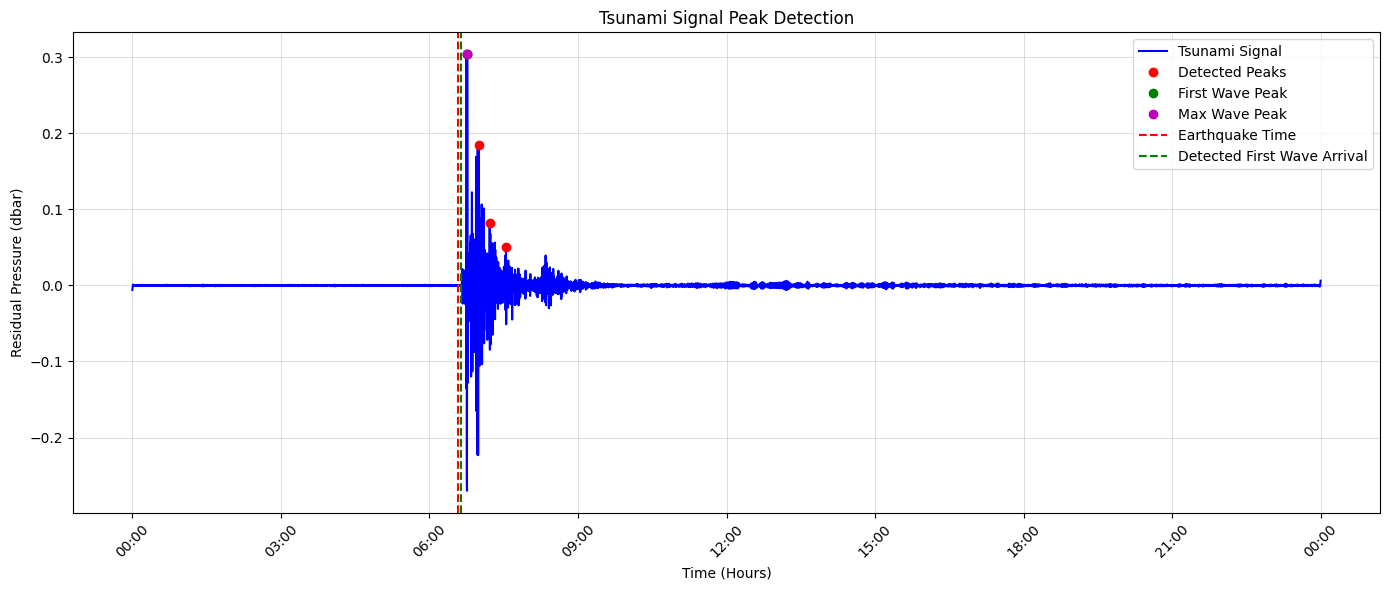

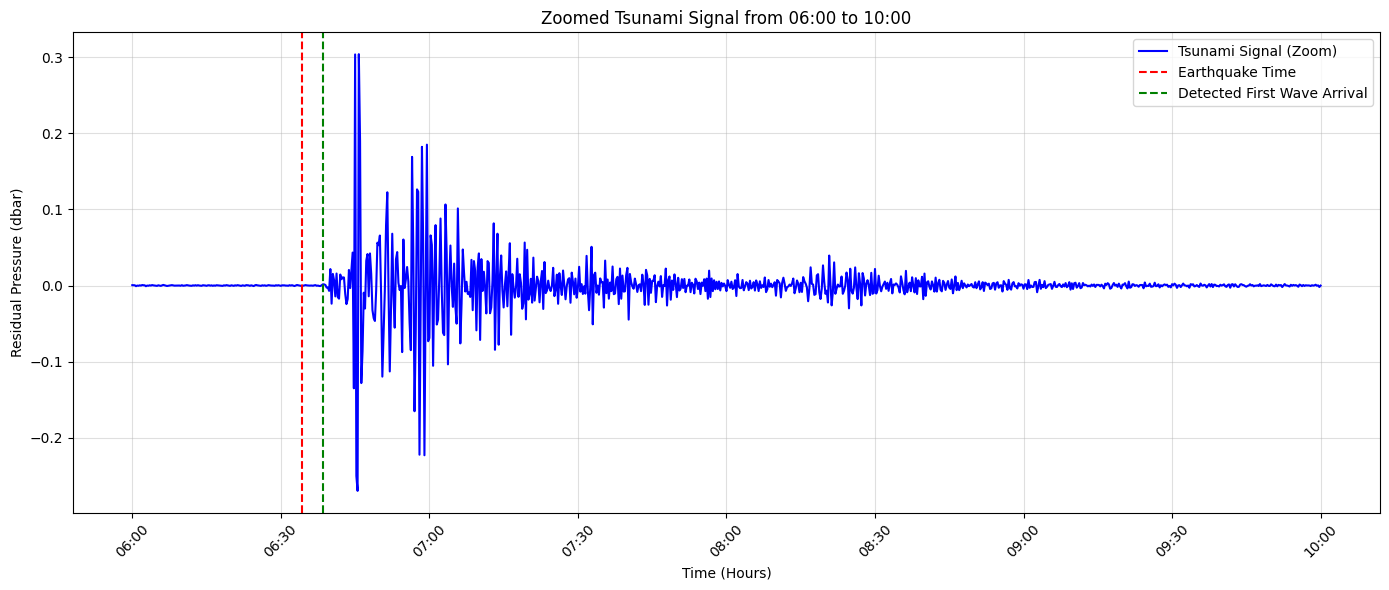

In [36]:

from scipy.signal import find_peaks
import matplotlib.pyplot as plt


# Constants
SEAWATER_DENSITY = 1025  # kg/m³
GRAVITY = 9.81           # m/s²
DBAR_TO_PA = 10000       # Pa per dbar
AMPLIFICATION_FACTOR = 20  # Typical coastal amplification factor

# Earthquake origin and locations
earthquake_time = pd.Timestamp("2010-02-27 06:34:12")
lat_epicenter, lon_epicenter = -35.909, -72.733
lat_coast, lon_coast = -36.5, -73.0

def haversine(lat1, lon1, lat2, lon2):
    R = 6371000.0
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat/2)**2 +
         np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2)
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

# Calculate travel time (optional, currently not used in plots)
dist_meters = haversine(lat_epicenter, lon_epicenter, lat_coast, lon_coast)
avg_depth = 4000
wave_speed = np.sqrt(GRAVITY * avg_depth)
travel_time_sec = dist_meters / wave_speed
coastal_arrival_time = earthquake_time + pd.Timedelta(seconds=travel_time_sec)
print(f"Theoretical coastal arrival time: {coastal_arrival_time}")

# Use full DataFrame df_filtered with DateTimeIndex and 'Tsunami_Signal' column
time_index = df_filtered.index
signal = df_filtered['Tsunami_Signal'].values

# Estimate baseline noise std from data before earthquake
noise_window_end = earthquake_time - pd.Timedelta(minutes=5)
noise_std = df_filtered.loc[:noise_window_end]['Tsunami_Signal'].std()
threshold = 3 * noise_std

# Detect first wave arrival: first time signal exceeds threshold
indices_above_thresh = np.where(signal > threshold)[0]
first_wave_idx = indices_above_thresh[0] if len(indices_above_thresh) > 0 else None
first_wave_datetime = time_index[first_wave_idx] if first_wave_idx is not None else None
if first_wave_datetime:
    print(f"Data-driven first wave arrival detected at {first_wave_datetime}")
else:
    print("No significant first wave arrival detected")

# Detect peaks for wave height estimation
peaks, props = find_peaks(signal, height=np.mean(signal) + 3*np.std(signal), distance=50)
peak_heights = props.get('peak_heights', signal[peaks])

def pressure_to_height(dbar):
    pa = dbar * DBAR_TO_PA
    uncalibrated_height = pa / (SEAWATER_DENSITY * GRAVITY)
    calibration_gain = 1.5
    calibration_offset = 0.05
    return calibration_gain * uncalibrated_height + calibration_offset

if len(peaks) > 0:
    first_peak_idx = peaks[0]
    max_peak_idx = peaks[np.argmax(peak_heights)]
    first_wave_height = pressure_to_height(signal[first_peak_idx])
    max_wave_height = pressure_to_height(signal[max_peak_idx])
    est_max_coastal_amplitude = max_wave_height * AMPLIFICATION_FACTOR
else:
    first_peak_idx = max_peak_idx = None
    est_max_coastal_amplitude = None
    print("No significant peaks detected.")

print(f"Maximum residual offshore pressure: {signal[max_peak_idx] if max_peak_idx is not None else 'N/A'} dbar")
print(f"Calibrated max offshore height: {max_wave_height:.4f} m" if max_peak_idx is not None else "")
print(f"Estimated maximum coastal amplitude (run-up): {est_max_coastal_amplitude:.4f} m" if est_max_coastal_amplitude is not None else "")

# Plot 1: Peak detection with peaks and actual first wave arrival
plt.figure(figsize=(14, 6))
plt.plot(time_index, signal, color='blue', label='Tsunami Signal')
if len(peaks) > 0:
    plt.plot(time_index[peaks], signal[peaks], 'ro', label='Detected Peaks')
    plt.plot(time_index[first_peak_idx], signal[first_peak_idx], 'go', label='First Wave Peak')
    plt.plot(time_index[max_peak_idx], signal[max_peak_idx], 'mo', label='Max Wave Peak')
plt.axvline(earthquake_time, color='red', linestyle='--', label='Earthquake Time')
if first_wave_datetime is not None:
    plt.axvline(first_wave_datetime, color='green', linestyle='--', label='Detected First Wave Arrival')

plt.title('Tsunami Signal Peak Detection')
plt.xlabel('Time (Hours)')
plt.ylabel('Residual Pressure (dbar)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot 2: Zoom from 06:00 to 10:00 with actual first wave arrival only
zoom_start = pd.Timestamp("2010-02-27 06:00:00")
zoom_end = pd.Timestamp("2010-02-27 10:00:00")
zoom_mask = (time_index >= zoom_start) & (time_index <= zoom_end)

plt.figure(figsize=(14, 6))
plt.plot(time_index[zoom_mask], signal[zoom_mask], label='Tsunami Signal (Zoom)', color='blue')
plt.axvline(earthquake_time, color='red', linestyle='--', label='Earthquake Time')
if first_wave_datetime is not None:
    plt.axvline(first_wave_datetime, color='green', linestyle='--', label='Detected First Wave Arrival')

plt.title('Zoomed Tsunami Signal from 06:00 to 10:00')
plt.xlabel('Time (Hours)')
plt.ylabel('Residual Pressure (dbar)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

